# Projeto 2 — Computação Visual
## Redimensionamento inteligente de imagens usando *Seam Carving*

**Opção 2: tutorial de teoria e prática | Universidade Presbiteriana Mackenzie**  
**Disciplina:** Computação Visual · **Professor:** André Kishimoto

**Integrantes**

- **Beatriz Aparecida de Mello Barbosa** — RA: **10354067**
- **Henrique Jeam Ferreira Lima** — RA: **10277156**

**Objetivo:** compreender o algoritmo *Seam Carving*, implementar uma versão didática com programação dinâmica e comparar seus resultados com o redimensionamento convencional.

> **Organização:** (1) fundamentos, (2) implementação, (3) experimentos e análise, (4) conclusões e referências. Execute as células de cima para baixo, ou use **Run All**.

## 1. Introdução e problema

Redimensionar uma imagem é necessário ao adaptar fotografias a diferentes formatos de tela, páginas web e layouts. No método **convencional**, a imagem é reamostrada para as dimensões desejadas. Quando a proporção original não é mantida, pessoas e objetos podem ficar estreitos ou largos.

O **Seam Carving**, apresentado por Avidan e Shamir (2007), é um método de **redimensionamento orientado pelo conteúdo** (*content-aware image resizing*). Para reduzir a largura, ele identifica um caminho vertical formado por **um pixel em cada linha**, cujos pixels vizinhos pertencem a colunas iguais ou adjacentes. Esse caminho é chamado *seam* (costura). O algoritmo remove um caminho de baixo custo e repete o processo até atingir a largura desejada.

A ideia é **retirar, sempre que possível, partes visualmente menos relevantes** em vez de comprimir toda a cena. Assim, objetos podem manter melhor suas proporções. É importante notar que a preservação **não é garantida**: ela depende da função de energia, da imagem e da intensidade da redução.

### O que será implementado

- Cálculo de um **mapa de energia** a partir de gradientes de intensidade.
- Busca do caminho vertical de **menor custo total**, usando programação dinâmica.
- **Remoção** de seams sucessivos e redução da altura via transposição da imagem.
- Recurso extra: **máscara de proteção** para desencorajar a remoção de regiões importantes.
- Experimentos com fotografias e comparação com **reamostragem bicúbica**.

**Escopo:** implementamos a *redução*, não a inserção de seams (ampliação), nem a energia prospectiva (*forward energy*).

## 2. Fundamentos teóricos

### 2.1. Mapa de energia

Uma imagem digital colorida é uma matriz de pixels com canais R, G e B. Para estimar a importância local de cada posição, primeiro aproximamos o brilho de cada pixel por

$$I = 0{,}2126R + 0{,}7152G + 0{,}0722B.$$

Nesta implementação didática, usamos as **diferenças numéricas** desse brilho nas direções horizontal e vertical. A energia da posição $(y,x)$ é

$$E(y,x) = \left|\frac{\partial I}{\partial x}\right| + \left|\frac{\partial I}{\partial y}\right|.$$

Regiões de transição de cor/intensidade normalmente têm energia mais alta; regiões relativamente homogêneas têm energia menor. Esta é uma **aproximação simples baseada em gradientes**; não mede diretamente a importância semântica de rostos ou objetos.

### 2.2. O que é um seam?

Em uma imagem de altura $H$ e largura $W$, um **seam vertical** é uma sequência

$$s=\{(y,x_y)\}_{y=0}^{H-1}, \qquad |x_y-x_{y-1}|\leq 1,$$

ou seja, há exatamente um pixel por linha, e o deslocamento de uma linha para a seguinte é, no máximo, uma coluna.

A soma das energias dos pixels do caminho é o seu custo:

$$C(s)=\sum_{y=0}^{H-1} E(y,x_y).$$

Nosso objetivo é encontrar o seam de **menor custo acumulado**, e não simplesmente escolher o pixel de menor energia em cada linha — escolhas locais não garantem o melhor caminho global.

### 2.3. Programação dinâmica

Definimos $M(y,x)$ como a energia mínima acumulada de um caminho que termina em $(y,x)$. Na primeira linha, $M(0,x)=E(0,x)$. Nas demais linhas:

$$M(y,x)=E(y,x)+\min\{M(y-1,x-1),M(y-1,x),M(y-1,x+1)\}.$$

Nas bordas, apenas os vizinhos **válidos** são considerados. Guardamos a posição do melhor predecessor de cada pixel; ao final, começamos no menor valor da última linha e reconstruímos o caminho de baixo para cima. Após remover esse caminho, **recalculamos a energia**, porque os vizinhos dos pixels mudam.

### 2.4. Alteração da altura

Para reduzir a altura, transpomos temporariamente a imagem (trocamos linhas e colunas), executamos a mesma operação de remoção vertical e transpomos novamente.

### 2.5. Custo computacional e limitações

Para uma imagem $H\times W$, uma busca por seam ocupa tempo proporcional a $H\cdot W$ e matrizes auxiliares da mesma ordem. Para remover $k$ seams, repetindo o cálculo de energia, o custo aproximado é **$O(kHW)$** para reduções moderadas. Esse método é mais lento que um redimensionamento geométrico simples e pode distorcer estruturas repetitivas ou áreas importantes mal representadas pela energia.

## 3. Ambiente e carregamento das imagens

O tutorial funciona com **Python 3, NumPy, Pillow e Matplotlib**. Os arquivos `imagens/foguete.png` e `imagens/astronauta.png` acompanham a entrega; **não é necessário baixar imagens da internet**.

Foguete (altura, largura, canais): (294, 440, 3)
Astronauta (altura, largura, canais): (320, 320, 3)


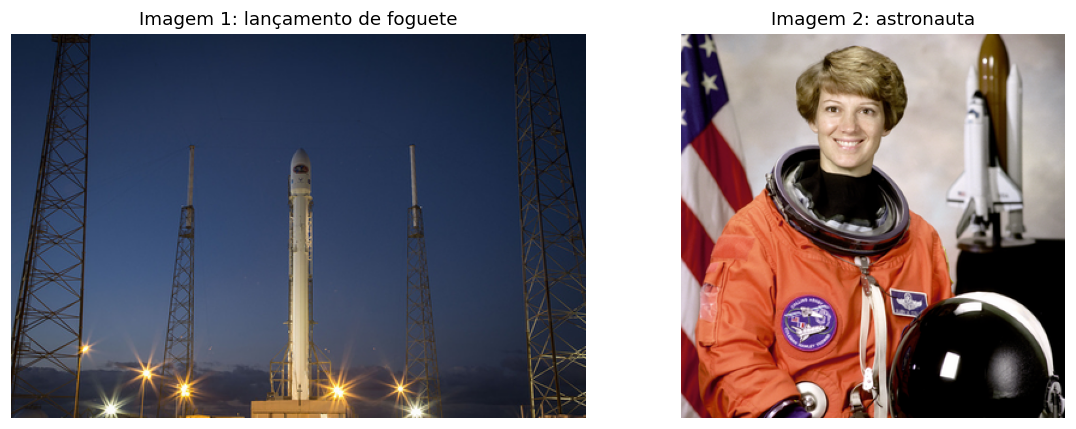

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
RAIZ = Path.cwd()
PASTA_IMAGENS = RAIZ / 'imagens'
PASTA_RESULTADOS = RAIZ / 'resultados'
PASTA_RESULTADOS.mkdir(exist_ok=True)

# Em um Jupyter local, abra este notebook dentro da pasta Projeto2_SeamCarving.
def abrir_rgb(nome):
    caminho = PASTA_IMAGENS / nome
    if not caminho.exists():
        raise FileNotFoundError(
            f'Imagem ausente: {caminho}. Abra o notebook na pasta do projeto, '
            'preservando a subpasta imagens/.')
    return np.asarray(Image.open(caminho).convert('RGB'), dtype=np.uint8)

foguete = abrir_rgb('foguete.png')
astronauta = abrir_rgb('astronauta.png')
print('Foguete (altura, largura, canais):', foguete.shape)
print('Astronauta (altura, largura, canais):', astronauta.shape)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].imshow(foguete)
eixos[0].set_title('Imagem 1: lançamento de foguete')
eixos[1].imshow(astronauta)
eixos[1].set_title('Imagem 2: astronauta')
for eixo in eixos: eixo.axis('off')
plt.tight_layout()
plt.show()

## 4. Implementação passo a passo

### 4.1. Transformação em níveis de cinza e cálculo da energia

Usamos `np.gradient`, que calcula diferenças numéricas, para aproximar a variação espacial do brilho. A saída tem uma energia não negativa por pixel.

In [2]:
def calcular_energia(imagem):
    """Retorna energia HxW pelo módulo dos gradientes do brilho."""
    imagem = np.asarray(imagem)
    if imagem.ndim != 3 or imagem.shape[2] != 3:
        raise ValueError('A imagem deve ter formato (altura, largura, 3), RGB.')
    if min(imagem.shape[:2]) < 2:
        raise ValueError('A imagem deve ter ao menos 2 pixels por dimensão.')
    rgb = imagem.astype(np.float64)
    brilho = (0.2126 * rgb[:, :, 0] +
              0.7152 * rgb[:, :, 1] +
              0.0722 * rgb[:, :, 2])
    dy, dx = np.gradient(brilho)
    return np.abs(dx) + np.abs(dy)

energia_foguete = calcular_energia(foguete)
print(f'Energia: mínimo={energia_foguete.min():.2f}, '
      f'máximo={energia_foguete.max():.2f}, média={energia_foguete.mean():.2f}')

Energia: mínimo=0.00, máximo=162.53, média=5.40


### 4.2. Menor seam vertical usando programação dinâmica

O algoritmo começa na primeira linha do mapa de energia, acumula o menor custo possível para alcançar cada pixel e depois reconstrói o caminho ótimo por retrocesso (*backtracking*).

In [3]:
def encontrar_seam_vertical(energia):
    """Retorna colunas do seam mínimo: vetor de tamanho altura."""
    energia = np.asarray(energia, dtype=np.float64)
    if energia.ndim != 2 or min(energia.shape) < 2:
        raise ValueError('Energia deve ser uma matriz HxW, com H,W >= 2.')
    altura, largura = energia.shape
    acumulada = np.empty((altura, largura), dtype=np.float64)
    predecessores = np.empty((altura, largura), dtype=np.int32)
    acumulada[0] = energia[0]
    predecessores[0] = -1
    colunas = np.arange(largura)

    for y in range(1, altura):
        # +infinito nas bordas evita passar por índices fora da imagem.
        anterior = np.pad(acumulada[y - 1], (1, 1),
                          mode='constant', constant_values=np.inf)
        candidatos = np.stack((anterior[:-2], anterior[1:-1],
                               anterior[2:]), axis=0)
        escolha = np.argmin(candidatos, axis=0)
        predecessores[y] = colunas + escolha - 1
        acumulada[y] = energia[y] + candidatos[escolha, colunas]

    seam = np.empty(altura, dtype=np.int32)
    seam[-1] = np.argmin(acumulada[-1])
    for y in range(altura - 2, -1, -1):
        seam[y] = predecessores[y + 1, seam[y + 1]]
    return seam

primeiro_seam = encontrar_seam_vertical(energia_foguete)
print('Seam encontrado:', len(primeiro_seam), 'pixels conectados.')
print('Custo total do seam:', round(float(
    energia_foguete[np.arange(len(primeiro_seam)), primeiro_seam].sum()), 2))

Seam encontrado: 294 pixels conectados.
Custo total do seam: 93.11


### 4.3. Visualização: energia e seam

A linha vermelha representa **um caminho inteiro**, e não apenas pontos independentes. O mapa de energia permite visualizar onde o algoritmo encontra regiões mais suaves.

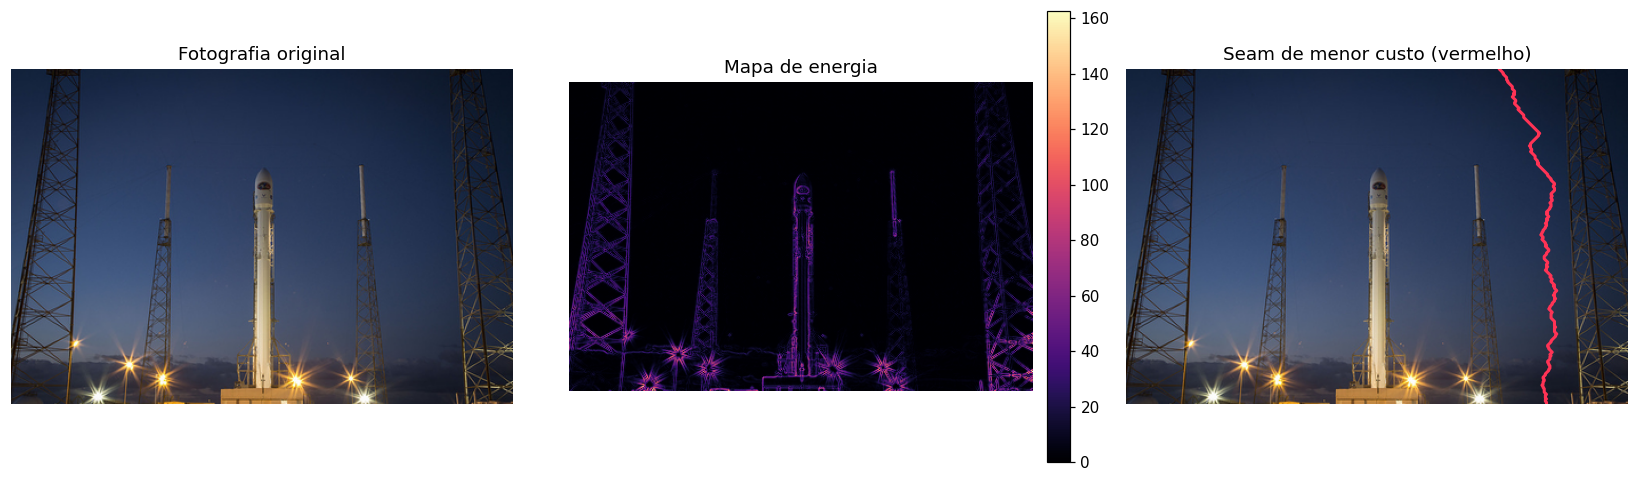

In [4]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.4))
eixos[0].imshow(foguete)
eixos[0].set_title('Fotografia original')
im = eixos[1].imshow(energia_foguete, cmap='magma')
eixos[1].set_title('Mapa de energia')
fig.colorbar(im, ax=eixos[1], fraction=0.046, pad=0.03)
eixos[2].imshow(foguete)
eixos[2].plot(primeiro_seam, np.arange(len(primeiro_seam)),
              color='#FF3355', linewidth=2.0)
eixos[2].set_title('Seam de menor custo (vermelho)')
for eixo in eixos: eixo.axis('off')
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / '01_mapa_de_energia_e_seam.png',
            dpi=150, bbox_inches='tight')
plt.show()

### 4.4. Remoção de um seam

Em cada linha, excluímos o pixel na coluna correspondente ao seam. Isso reduz a **largura em exatamente um pixel**, mantendo a altura.

In [5]:
def remover_seam_vertical(arranjo, seam):
    """Remove um pixel por linha de um array 2-D ou 3-D."""
    arranjo = np.asarray(arranjo)
    altura, largura = arranjo.shape[:2]
    seam = np.asarray(seam)
    if seam.shape != (altura,) or np.any(seam < 0) or np.any(seam >= largura):
        raise ValueError('Seam inválido para as dimensões da imagem.')
    if largura <= 1:
        raise ValueError('Não é possível remover seam com largura <= 1.')
    mascara = np.ones((altura, largura), dtype=bool)
    mascara[np.arange(altura), seam] = False
    if arranjo.ndim == 2:
        return arranjo[mascara].reshape(altura, largura - 1)
    if arranjo.ndim == 3:
        return arranjo[mascara].reshape(altura, largura - 1, arranjo.shape[2])
    raise ValueError('O arranjo deve ter 2 ou 3 dimensões.')

foguete_1_seam = remover_seam_vertical(foguete, primeiro_seam)
print('Antes:', foguete.shape, '| Depois de 1 seam:', foguete_1_seam.shape)

Antes: (294, 440, 3) | Depois de 1 seam: (294, 439, 3)


### 4.5. Repetir a remoção até chegar ao tamanho desejado

A energia muda após cada exclusão, por isso recalculamos tudo. Para reduzir a altura, reutilizamos a mesma função após trocar os eixos.

In [6]:
def _reduzir_colunas(imagem, largura_destino, mascara=None, peso_protecao=1e5):
    atual = imagem.copy()
    protecao = None if mascara is None else np.asarray(mascara, dtype=bool).copy()
    if protecao is not None and protecao.shape != atual.shape[:2]:
        raise ValueError('A máscara deve ter exatamente a altura e largura da imagem.')
    if not 1 <= largura_destino <= atual.shape[1]:
        raise ValueError('A largura de destino deve estar entre 1 e a largura original.')

    while atual.shape[1] > largura_destino:
        energia = calcular_energia(atual)
        if protecao is not None:
            # O acréscimo desencoraja remover pixels marcados, sem garantia absoluta.
            energia = energia + peso_protecao * protecao
        seam = encontrar_seam_vertical(energia)
        atual = remover_seam_vertical(atual, seam)
        if protecao is not None:
            protecao = remover_seam_vertical(protecao, seam)
    return atual, protecao


def seam_carving(imagem, nova_largura=None, nova_altura=None,
                 mascara_protecao=None, peso_protecao=1e5):
    """Reduz imagem RGB à largura/altura indicadas, opcionalmente com proteção."""
    imagem = np.asarray(imagem)
    if imagem.ndim != 3 or imagem.shape[2] != 3:
        raise ValueError('Esperada imagem RGB com 3 canais.')
    altura, largura = imagem.shape[:2]
    nova_largura = largura if nova_largura is None else int(nova_largura)
    nova_altura = altura if nova_altura is None else int(nova_altura)
    if not (2 <= nova_largura <= largura and 2 <= nova_altura <= altura):
        raise ValueError('Esta versão faz somente reduções, mantendo ao menos 2 pixels por eixo.')

    reduzida, mascara = _reduzir_colunas(imagem, nova_largura,
                                         mascara_protecao, peso_protecao)
    if nova_altura < altura:
        girada = np.transpose(reduzida, (1, 0, 2))
        mascara_girada = None if mascara is None else mascara.T
        girada, _ = _reduzir_colunas(girada, nova_altura,
                                    mascara_girada, peso_protecao)
        reduzida = np.transpose(girada, (1, 0, 2))
    return reduzida

### 4.6. Testes de correção

Os testes abaixo verificam três propriedades importantes: o seam é conectado, a remoção diminui uma coluna e a redução da altura/largura retorna as dimensões pedidas.

In [7]:
energia_teste = np.array([
    [8, 1, 8, 8],
    [8, 1, 8, 8],
    [8, 1, 8, 8],
    [8, 1, 8, 8]], dtype=float)
seam_teste = encontrar_seam_vertical(energia_teste)
assert np.array_equal(seam_teste, [1, 1, 1, 1])
assert np.all(np.abs(np.diff(seam_teste)) <= 1)

imagem_teste = np.arange(6 * 7 * 3, dtype=np.uint8).reshape(6, 7, 3)
removida_teste = remover_seam_vertical(imagem_teste, np.ones(6, dtype=int))
assert removida_teste.shape == (6, 6, 3)
assert seam_carving(imagem_teste, nova_largura=5, nova_altura=4).shape == (4, 5, 3)
print('Testes concluídos: caminho válido, remoção correta e tamanho final correto.')

Testes concluídos: caminho válido, remoção correta e tamanho final correto.


## 5. Experimento A — comparação com redimensionamento convencional

Escolhemos a imagem do foguete, originalmente **440 × 294 pixels**, e reduzimos **a largura para 350 pixels** mantendo a altura. O método convencional (bicúbico) interpola os pixels em toda a largura; o Seam Carving remove caminhos sucessivos de baixa energia.

Original: 440 x 294
Bicúbico: 350 x 294
Seam Carving: 350 x 294
Largura reduzida em 20.454545454545453 % (aproximadamente).


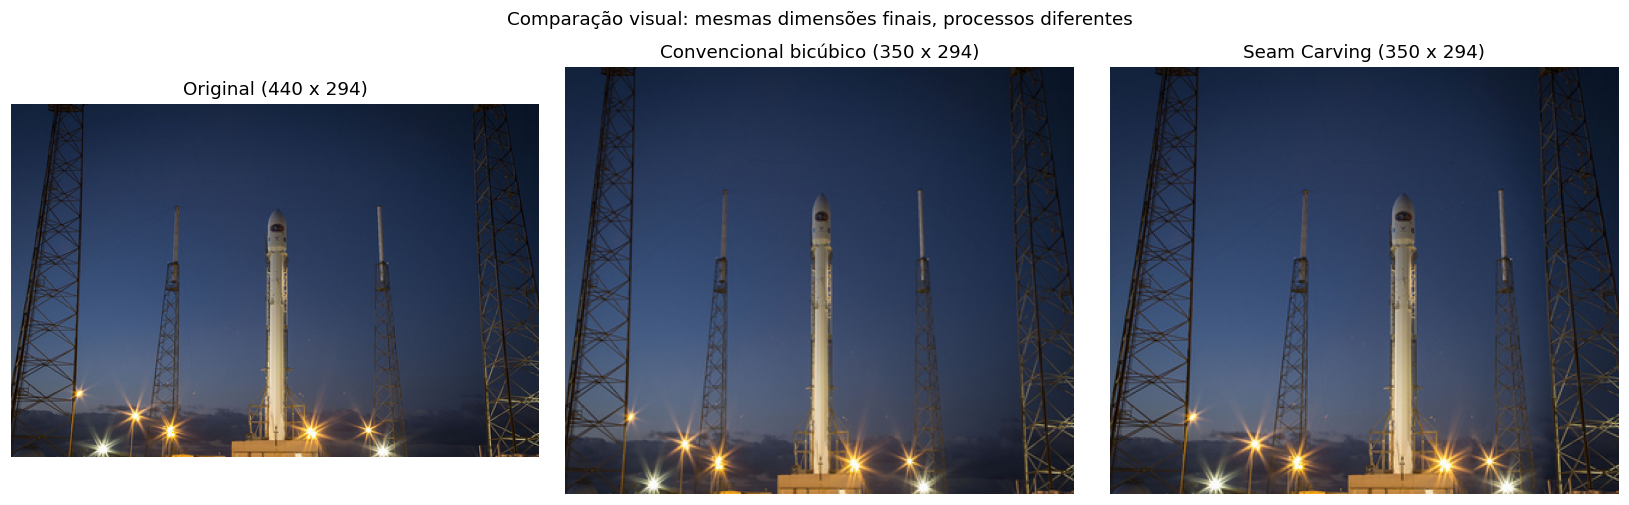

In [8]:
LARGURA_ALVO = 350
bicubico = np.asarray(
    Image.fromarray(foguete).resize((LARGURA_ALVO, foguete.shape[0]),
                                      Image.Resampling.BICUBIC))
inteligente = seam_carving(foguete, nova_largura=LARGURA_ALVO)
print('Original:', foguete.shape[1], 'x', foguete.shape[0])
print('Bicúbico:', bicubico.shape[1], 'x', bicubico.shape[0])
print('Seam Carving:', inteligente.shape[1], 'x', inteligente.shape[0])
print('Largura reduzida em', 100 * (foguete.shape[1] - LARGURA_ALVO) /
      foguete.shape[1], '% (aproximadamente).')

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
for eixo, img, titulo in zip(eixos,
     [foguete, bicubico, inteligente],
     ['Original (440 x 294)', 'Convencional bicúbico (350 x 294)',
      'Seam Carving (350 x 294)']):
    eixo.imshow(img)
    eixo.set_title(titulo)
    eixo.axis('off')
plt.suptitle('Comparação visual: mesmas dimensões finais, processos diferentes',y=1.01)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / '02_comparacao_foguete.png',
            dpi=160, bbox_inches='tight')
plt.show()

### Leitura dos resultados

- **Bicúbico:** mantém todo o conteúdo, mas **comprime horizontalmente** a cena para caber na nova largura; objetos verticais ficam relativamente mais estreitos.
- **Seam Carving:** procura reduzir regiões de menor energia, buscando preservar as partes de maior contraste. A largura final é idêntica à do método convencional, mas a distribuição das remoções não é uniforme.
- **Possíveis artefatos:** torres, linhas retas, texturas e outros elementos podem sofrer deformações locais porque a função de energia não compreende o significado de cada objeto.

Esses pontos são uma **análise qualitativa visual**, e não uma afirmação de superioridade universal. Não calculamos uma métrica numérica de qualidade perceptual, pois o algoritmo modifica a geometria do conteúdo e um erro pixel a pixel em relação à imagem original não seria diretamente comparável.

## 6. Experimento B — proteção de região importante

Nesta segunda fotografia, mostramos uma funcionalidade opcional: adicionar **um custo alto** à energia de uma região marcada manualmente. Criamos uma máscara retangular cobrindo aproximadamente o rosto e o cabelo da astronauta. Isso reduz a chance de que o algoritmo retire pixels dessa região, mas não garante que todo o seu entorno fique inalterado.

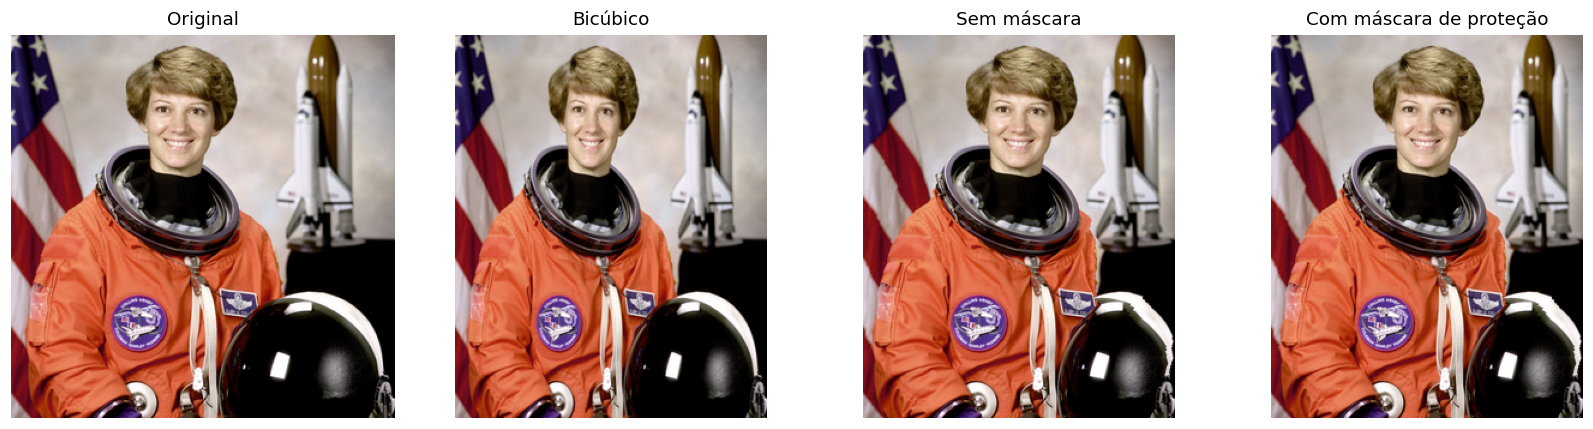

In [9]:
# Coordenadas (linha/coluna) escolhidas para esta fotografia de 320 x 320.
mascara_rosto = np.zeros(astronauta.shape[:2], dtype=bool)
mascara_rosto[17:123, 93:201] = True

# Redução de 320 para 260 colunas (60 seams).
DESTINO_ASTRONAUTA = 260
astronauta_convencional = np.asarray(
    Image.fromarray(astronauta).resize((DESTINO_ASTRONAUTA, 320),
                                       Image.Resampling.BICUBIC))
astronauta_sem_mascara = seam_carving(astronauta, nova_largura=DESTINO_ASTRONAUTA)
astronauta_com_mascara = seam_carving(
    astronauta, nova_largura=DESTINO_ASTRONAUTA,
    mascara_protecao=mascara_rosto)

fig, eixos = plt.subplots(1, 4, figsize=(15, 4))
for eixo, img, titulo in zip(eixos,
    [astronauta, astronauta_convencional,
     astronauta_sem_mascara, astronauta_com_mascara],
    ['Original', 'Bicúbico', 'Sem máscara', 'Com máscara de proteção']):
    eixo.imshow(img)
    eixo.set_title(titulo)
    eixo.axis('off')
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / '03_comparacao_astronauta.png',
            dpi=160, bbox_inches='tight')
plt.show()

Para visualizar a área **original** protegida, exibimos abaixo a máscara sobreposta ao rosto. Sua posição deve ser reajustada para outras imagens.

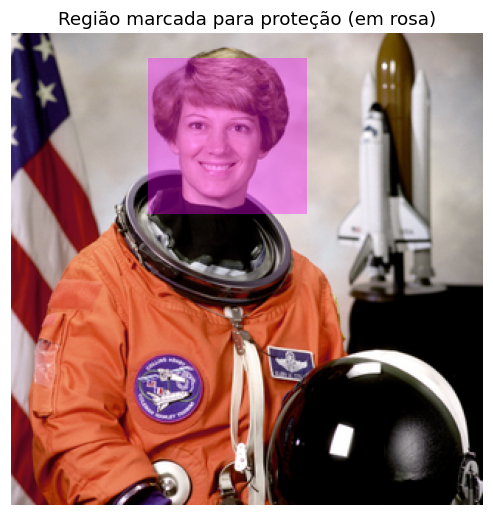

In [10]:
fig, eixo = plt.subplots(figsize=(4.8, 4.8))
eixo.imshow(astronauta)
eixo.imshow(np.ma.masked_where(~mascara_rosto, mascara_rosto),
            cmap='spring', alpha=0.36, interpolation='nearest')
eixo.set_title('Região marcada para proteção (em rosa)')
eixo.axis('off')
plt.tight_layout()
plt.show()

## 7. Discussão crítica

O experimento mostra que a escolha da função de energia altera quais pixels são removidos. **Bordas não são sinônimo perfeito de importância visual**: uma parede com muita textura pode receber mais energia que um rosto em uma região suave. Por isso, a máscara é útil quando se conhece antecipadamente a área que deve ser protegida.

**Outras limitações da nossa implementação:**

1. **Distorções locais:** linhas retas e estruturas geométricas podem ficar curvadas ou irregulares.
2. **Reduções intensas:** quando restam poucas regiões de baixa energia, o algoritmo precisa cortar caminhos cada vez mais relevantes.
3. **Custo de execução:** cada seam é pesquisado novamente, tornando grandes reduções mais lentas.
4. **Sem ampliação:** a inserção de seams não foi implementada neste tutorial.
5. **Energia simplificada:** usamos gradiente de brilho (*backward energy*). Rubinstein, Shamir e Avidan (2008) discutem uma formulação alternativa, *forward energy*, que considera perturbações provocadas pelas remoções.

A comparação permite concluir que **Seam Carving é uma alternativa útil para mudanças moderadas de proporção**, sobretudo quando há áreas menos importantes disponíveis. Sua vantagem depende da cena; para fotos com muitos elementos importantes, o redimensionamento tradicional ou uma combinação de métodos pode ser preferível.

## 8. Experimente você mesmo

Altere os valores e execute novamente as células correspondentes:

- No **Experimento A**, substitua `LARGURA_ALVO = 350` por `370` ou `390` e observe a diferença.
- No **Experimento B**, modifique o retângulo `mascara_rosto[17:123, 93:201]` e compare com o resultado sem proteção.
- Para testar outra imagem, salve um arquivo RGB em `imagens/`, carregue com `abrir_rgb('seu_arquivo.png')` e escolha uma largura **menor** que a original.
- Para reduzir **altura e largura ao mesmo tempo**, use `seam_carving(imagem, nova_largura=..., nova_altura=...)`.

**Questões para refletir:** (1) O que muda quando retiramos mais seams? (2) Uma região de baixa energia é sempre irrelevante? (3) Qual é a principal diferença entre remover caminhos e comprimir toda a imagem?

## 9. Conclusão

Neste tutorial, implementamos um algoritmo de redimensionamento inteligente de imagens a partir dos seguintes passos: converter pixels em um mapa de energia, buscar um caminho conectado de energia acumulada mínima, remover esse caminho e repetir até alcançar as dimensões pretendidas. A programação dinâmica torna a escolha de cada seam eficiente, enquanto a máscara de proteção oferece controle adicional sobre regiões de interesse.

Os experimentos com imagens reais mostram a **diferença entre compressão geométrica uniforme e remoção orientada pelo conteúdo**, bem como as limitações do método. O principal aprendizado é que um critério matemático simples de energia já permite adaptar a geometria de uma imagem de maneira não uniforme, mas a qualidade perceptual depende das estruturas presentes na cena.

## 10. Referências bibliográficas e créditos

1. **AVIDAN, Shai; SHAMIR, Ariel.** *Seam Carving for Content-Aware Image Resizing*. ACM Transactions on Graphics, v. 26, n. 3, 2007. DOI: [10.1145/1276377.1276390](https://doi.org/10.1145/1276377.1276390). Artigo original do método.
2. **RUBINSTEIN, Michael; SHAMIR, Ariel; AVIDAN, Shai.** *Improved Seam Carving for Video Retargeting*. ACM Transactions on Graphics, v. 27, n. 3, art. 16, 2008. DOI: [10.1145/1360612.1360615](https://doi.org/10.1145/1360612.1360615). Referência para aprimoramento *forward energy* (não implementado aqui).
3. **PILLOW.** *Image.resize — documentação de referência.* Disponível em: [pillow.readthedocs.io/en/stable/reference/Image.html](https://pillow.readthedocs.io/en/stable/reference/Image.html). Referência do redimensionamento bicúbico convencional.
4. **SCIKIT-IMAGE.** *skimage.data — imagens de exemplo e créditos*. Disponível em: [scikit-image.org/docs/stable/api/skimage.data](https://scikit-image.org/docs/stable/api/skimage.data). Créditos e licença das imagens utilizadas.

**Créditos das imagens:** `foguete.png` deriva da fotografia de lançamento do Falcon 9 disponibilizada pela **SpaceX**, em domínio público, via `skimage.data.rocket`; `astronauta.png` deriva da fotografia da astronauta **Eileen Collins**, disponibilizada pela **NASA**, em domínio público, via `skimage.data.astronaut`. As duas imagens foram reduzidas de resolução apenas para a execução didática; são distribuídas junto do notebook para execução offline.

**Ferramentas:** Python 3, NumPy, Matplotlib e Pillow. A implementação de Seam Carving foi redigida neste tutorial; **não usa bibliotecas prontas que realizam o algoritmo**.